In [1]:
# Imports
import qiskit
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

print("Qiskit Version:", qiskit.__version__)
simulator = AerSimulator()

def superdense_coding(message="00", bit_flip_error=False, shots=1024):
    if message not in {"00", "01", "10", "11"}:
        raise ValueError("Message must be 00, 01, 10, or 11")

    qc = QuantumCircuit(2, 2)
    qc.h(0)
    qc.cx(0, 1)  # shared |Phi+> Bell pair
    qc.barrier()

    if message[0] == "1":
        qc.z(0)
    if message[1] == "1":
        qc.x(0)
    qc.barrier()

    if bit_flip_error:
        qc.x(0)

    qc.cx(0, 1)
    qc.h(0)
    qc.measure([0, 1], [0, 1])

    counts = simulator.run(qc, shots=shots).result().get_counts()
    return qc, counts


def decoded_counts(counts):
    # Convert Qiskit displayed c1c0 keys to message order.
    return {key[::-1]: value for key, value in counts.items()}


def decoded_message(counts):
    return max(decoded_counts(counts), key=decoded_counts(counts).get)


Qiskit Version: 2.5.1


p=0.00, counts={'01': 4096}, estimated error=0.00%
p=0.01, counts={'01': 4022, '00': 37, '11': 36, '10': 1}, estimated error=1.81%
p=0.03, counts={'01': 3854, '00': 125, '11': 115, '10': 2}, estimated error=5.91%
p=0.05, counts={'01': 3678, '11': 189, '00': 216, '10': 13}, estimated error=10.21%
p=0.10, counts={'01': 3317, '10': 45, '00': 349, '11': 385}, estimated error=19.02%
p=0.15, counts={'01': 2967, '11': 502, '00': 527, '10': 100}, estimated error=27.56%


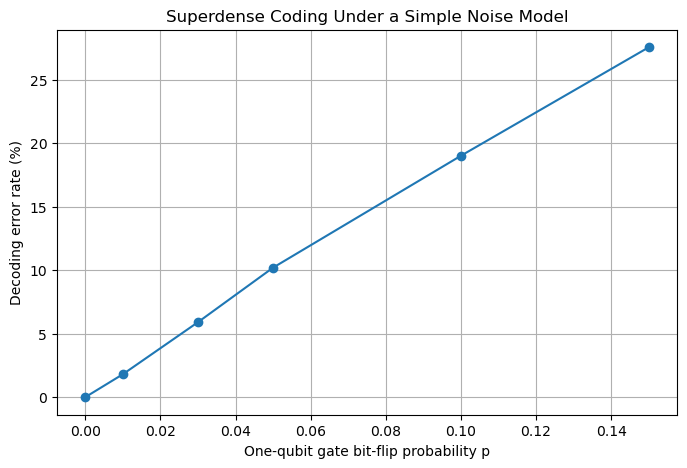

In [2]:
from qiskit_aer.noise import NoiseModel, pauli_error

def make_noise_model(p):
    model = NoiseModel()
    error = pauli_error([("X", p), ("I", 1-p)])
    model.add_all_qubit_quantum_error(error, ["h", "x", "z"])
    return model


def noisy_superdense(message="10", p=0.05, shots=4096):
    qc = QuantumCircuit(2, 2)
    qc.h(0)
    qc.cx(0, 1)

    if message[0] == "1":
        qc.z(0)
    if message[1] == "1":
        qc.x(0)

    qc.cx(0, 1)
    qc.h(0)
    qc.measure([0, 1], [0, 1])

    result = simulator.run(
        qc, shots=shots, noise_model=make_noise_model(p)
    ).result()
    return result.get_counts()


p_values = [0.00, 0.01, 0.03, 0.05, 0.10, 0.15]
message = "10"
error_rates = []

for p in p_values:
    counts = noisy_superdense(message=message, p=p)
    ordered = decoded_counts(counts)
    error_rate = 1 - ordered.get(message, 0) / sum(counts.values())
    error_rates.append(error_rate)
    print(f"p={p:.2f}, counts={counts}, estimated error={error_rate*100:.2f}%")

plt.figure(figsize=(8, 5))
plt.plot(p_values, [e*100 for e in error_rates], marker="o")
plt.xlabel("One-qubit gate bit-flip probability p")
plt.ylabel("Decoding error rate (%)")
plt.title("Superdense Coding Under a Simple Noise Model")
plt.grid()
plt.show()
